# Aadhithya S
# 3122245002001
# IT-A

## Experiment: Image Caption Generator using CNN and LSTM (MNIST Dataset)

### 1. Overview and Environment Setup
This experiment demonstrates an end-to-end Image Captioning pipeline using a **CNN Encoder** and **LSTM Decoder** on the **MNIST Handwritten Digit Dataset**.

- **Dataset**: MNIST (`tf.keras.datasets.mnist`)
- **CNN Encoder**: Extracts spatial features from 28x28 grayscale handwritten digit images.
- **LSTM Decoder**: Generates natural language descriptions word-by-word (e.g., *"a photo of the digit seven"*).
- **Framework**: TensorFlow / Keras

In [17]:
"""
Experiment: Image Caption Generator using CNN and LSTM (MNIST Dataset)
Author: Aadhithya S (3122245002001, IT-A)
========================================================================
"""

import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense,
    Embedding, LSTM, Add, Dropout
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


### 2. Dataset Loading & Caption Pair Generation
Load the MNIST dataset, normalize pixel values to `[0, 1]`, add channel dimensions, and generate varied natural language captions for each image class using caption templates.

In [18]:
# -------------------------------------------------------------------
# Load MNIST dataset
# -------------------------------------------------------------------
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize to [0,1] and add channel dimension: (N, 28, 28) -> (N, 28, 28, 1)
x_train = x_train.astype("float32")[..., np.newaxis] / 255.0
x_test = x_test.astype("float32")[..., np.newaxis] / 255.0

# Class names for digits 0-9
class_names = ["zero", "one", "two", "three", "four",
               "five", "six", "seven", "eight", "nine"]

# Caption templates per class for natural language variation
TEMPLATES = [
    "a photo of the digit {}",
    "this picture shows the number {}",
    "an image containing the digit {}",
    "a handwritten digit {}",
    "here is the number {}",
]

def make_caption(label_idx):
    name = class_names[label_idx]
    article_fix = "an " + name if name[0] in "aeiou" else "a " + name
    template = random.choice(TEMPLATES)
    caption = template.format(name).replace("a " + name, article_fix)
    return "startseq " + caption + " endseq"

# Subset for fast training during lab sessions
N_TRAIN, N_TEST = 4000, 500
train_idx = np.random.choice(len(x_train), N_TRAIN, replace=False)
test_idx = np.random.choice(len(x_test), N_TEST, replace=False)

train_images = x_train[train_idx]
train_captions = [make_caption(int(y_train[i])) for i in train_idx]
test_images = x_test[test_idx]
test_captions = [make_caption(int(y_test[i])) for i in test_idx]

print("Total training subset images:", train_images.shape)
print("Total test subset images:", test_images.shape)
print("\nSample Generated Captions:")
for i in range(5):
    print(f" Image {i} (Label: {y_train[train_idx[i]]}): {train_captions[i]}")

Total training subset images: (4000, 28, 28, 1)
Total test subset images: (500, 28, 28, 1)

Sample Generated Captions:
 Image 0 (Label: 7): startseq a photo of the digit seven endseq
 Image 1 (Label: 3): startseq a photo of the digit three endseq
 Image 2 (Label: 8): startseq an image containing the digit eight endseq
 Image 3 (Label: 9): startseq this picture shows the number nine endseq
 Image 4 (Label: 3): startseq this picture shows the number three endseq


### 3. Text Tokenization and Vocabulary Construction
Tokenize the text captions, build the word-to-index vocabulary, and determine maximum sequence length.

In [19]:
# -------------------------------------------------------------------
# Tokenize captions & build vocabulary
# -------------------------------------------------------------------
tokenizer = Tokenizer(oov_token="<unk>")
tokenizer.fit_on_texts(train_captions)
vocab_size = len(tokenizer.word_index) + 1
max_len = max(len(c.split()) for c in train_captions)

print(f"Vocabulary Size: {vocab_size}")
print(f"Maximum Caption Length: {max_len}")
print("Word Index Mapping:", tokenizer.word_index)

def encode_captions(captions):
    return tokenizer.texts_to_sequences(captions)

train_seqs = encode_captions(train_captions)
test_seqs = encode_captions(test_captions)

Vocabulary Size: 29
Maximum Caption Length: 8
Word Index Mapping: {'<unk>': 1, 'startseq': 2, 'endseq': 3, 'the': 4, 'digit': 5, 'a': 6, 'number': 7, 'handwritten': 8, 'an': 9, 'image': 10, 'containing': 11, 'here': 12, 'is': 13, 'this': 14, 'picture': 15, 'shows': 16, 'photo': 17, 'of': 18, 'nine': 19, 'one': 20, 'seven': 21, 'zero': 22, 'four': 23, 'three': 24, 'eight': 25, 'two': 26, 'five': 27, 'six': 28}


### 4. Sequence Expansion for Autoregressive Training
Expand each `(image, caption)` pair into training triplets: `(image, partial_caption_input, next_target_word)`.

In [20]:
# -------------------------------------------------------------------
# Expand sequences into training samples
# -------------------------------------------------------------------
def build_sequences(images, seqs):
    X_img, X_seq, y = [], [], []
    for img, seq in zip(images, seqs):
        for t in range(1, len(seq)):
            in_seq, out_word = seq[:t], seq[t]
            in_seq = pad_sequences([in_seq], maxlen=max_len)[0]
            X_img.append(img)
            X_seq.append(in_seq)
            y.append(out_word)
    return np.array(X_img), np.array(X_seq), to_categorical(y, num_classes=vocab_size)

X_img_train, X_seq_train, y_train_cap = build_sequences(train_images, train_seqs)
print("Expanded Training Triplets shape:")
print("  Image Inputs:", X_img_train.shape)
print("  Sequence Inputs:", X_seq_train.shape)
print("  Target Output Labels:", y_train_cap.shape)

Expanded Training Triplets shape:
  Image Inputs: (25562, 28, 28, 1)
  Sequence Inputs: (25562, 8)
  Target Output Labels: (25562, 29)


### 5. CNN Encoder + LSTM Decoder Model Architecture
Construct a dual-branch neural network:
1. **CNN Encoder Branch**: 2D Convolutions + Max Pooling + Global Average Pooling to encode image spatial features into a dense vector.
2. **LSTM Decoder Branch**: Word Embedding + LSTM Layer to encode text sequences seen so far.
3. **Merge Layer**: Combines visual and text representations using addition followed by Dense layers for next-word classification.

In [21]:


EMBED_DIM = 128

# ---- CNN Encoder Branch (Image input: 28x28x1)
image_input = Input(shape=(28, 28, 1), name="image_input")
cnn = Conv2D(32, (3, 3), activation="relu", padding="same")(image_input)
cnn = MaxPooling2D()(cnn)
cnn = Conv2D(64, (3, 3), activation="relu", padding="same")(cnn)
cnn = MaxPooling2D()(cnn)
cnn = GlobalAveragePooling2D()(cnn)
image_features = Dense(EMBED_DIM, activation="relu")(cnn)
image_features = Dropout(0.3)(image_features)

# ---- LSTM Decoder Branch (Caption sequence input)
seq_input = Input(shape=(max_len,), name="caption_input")
seq_embed = Embedding(vocab_size, EMBED_DIM, mask_zero=True)(seq_input)
seq_embed = Dropout(0.3)(seq_embed)
seq_features = LSTM(EMBED_DIM, use_cudnn=False)(seq_embed)

# ---- Merge Features & Predict Next Word
merged = Add()([image_features, seq_features])
merged = Dense(EMBED_DIM, activation="relu")(merged)
output = Dense(vocab_size, activation="softmax")(merged)

caption_model = Model(inputs=[image_input, seq_input], outputs=output)
caption_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

caption_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 28, 28,    │        320 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 14, 14,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 14, 14,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 7, 7, 64)  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_input       │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_3[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 8, 128)    │      3,712 │ caption_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │      8,320 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 8, 128)    │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 8)         │          0 │ caption_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 128)       │    131,584 │ dropout_3[0][0],  │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128)       │          0 │ dropout_2[0][0],  │
│                     │                   │            │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     16,512 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 29)        │      3,741 │ dense_4[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 182,685 (713.61 KB)

 Trainable params: 182,685 (713.61 KB)

 Non-trainable params: 0 (0.00 B)

### 6. Model Training & Loss Visualization
Train the combined CNN-LSTM model and visualize the categorical cross-entropy loss across epochs.

Epoch 1/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.6387 - loss: 1.0869 - val_accuracy: 0.7501 - val_loss: 0.6013
Epoch 2/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7525 - loss: 0.5757 - val_accuracy: 0.7595 - val_loss: 0.5408
Epoch 3/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7629 - loss: 0.5400 - val_accuracy: 0.7657 - val_loss: 0.5230
Epoch 4/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7730 - loss: 0.5137 - val_accuracy: 0.7873 - val_loss: 0.4789
Epoch 5/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7888 - loss: 0.4782 - val_accuracy: 0.8009 - val_loss: 0.4461
Epoch 6/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8000 - loss: 0.4486 - val_accuracy: 0.8099 - val_loss: 0.4237
Epoch 7/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8124 - loss: 0.4224 - val_accuracy: 0.8178 - val_loss: 0.4045
Epoch 8/10
360/360 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8212 - loss: 0.4007 - val_accuracy: 

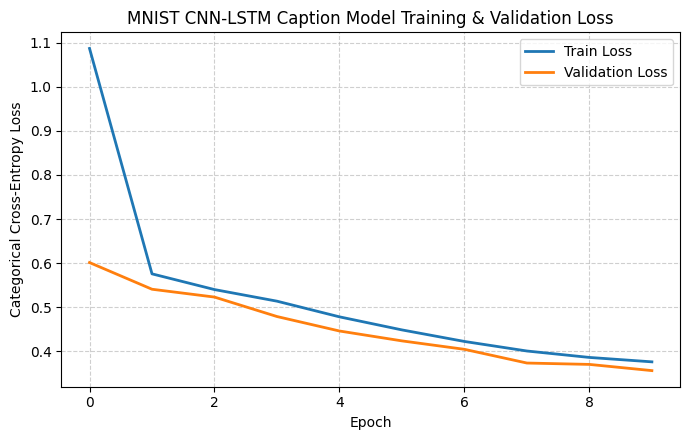

In [22]:
# -------------------------------------------------------------------
# Train Model
# -------------------------------------------------------------------
history = caption_model.fit(
    [X_img_train, X_seq_train], y_train_cap,
    epochs=10, batch_size=64, validation_split=0.1, verbose=1
)

plt.figure(figsize=(7, 4.5))
plt.plot(history.history["loss"], label="Train Loss", linewidth=2)
plt.plot(history.history["val_loss"], label="Validation Loss", linewidth=2)
plt.title("MNIST CNN-LSTM Caption Model Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Categorical Cross-Entropy Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()
plt.close()

### 7. Greedy Caption Inference Generator
Define a function to generate full text captions step-by-step using greedy search decoding starting from `startseq` until `endseq` or max length is reached.

In [23]:
# -------------------------------------------------------------------
# Greedy Decoding Inference
# -------------------------------------------------------------------
index_to_word = {idx: word for word, idx in tokenizer.word_index.items()}

def generate_caption(image, max_length=max_len):
    in_text = "startseq"
    for _ in range(max_length):
        seq = tokenizer.texts_to_sequences([in_text])[0]
        seq = pad_sequences([seq], maxlen=max_length)
        pred = caption_model.predict([np.expand_dims(image, 0), seq], verbose=0)
        next_idx = int(np.argmax(pred))
        next_word = index_to_word.get(next_idx, "")
        if next_word == "" or next_word == "endseq":
            break
        in_text += " " + next_word
    return in_text.replace("startseq", "").strip()

# Test sample caption generation
sample_img = test_images[0]
sample_label = class_names[int(y_test[test_idx[0]])]
print(f"True Label: {sample_label}")
print(f"Generated Caption: '{generate_caption(sample_img)}'")

True Label: six
Generated Caption: 'a handwritten digit two'


### 8. Evaluating & Visualizing Predictions on Unseen Test Images
Display sample unseen handwritten digit images from the test set alongside their ground truth class labels and model-generated natural language captions.

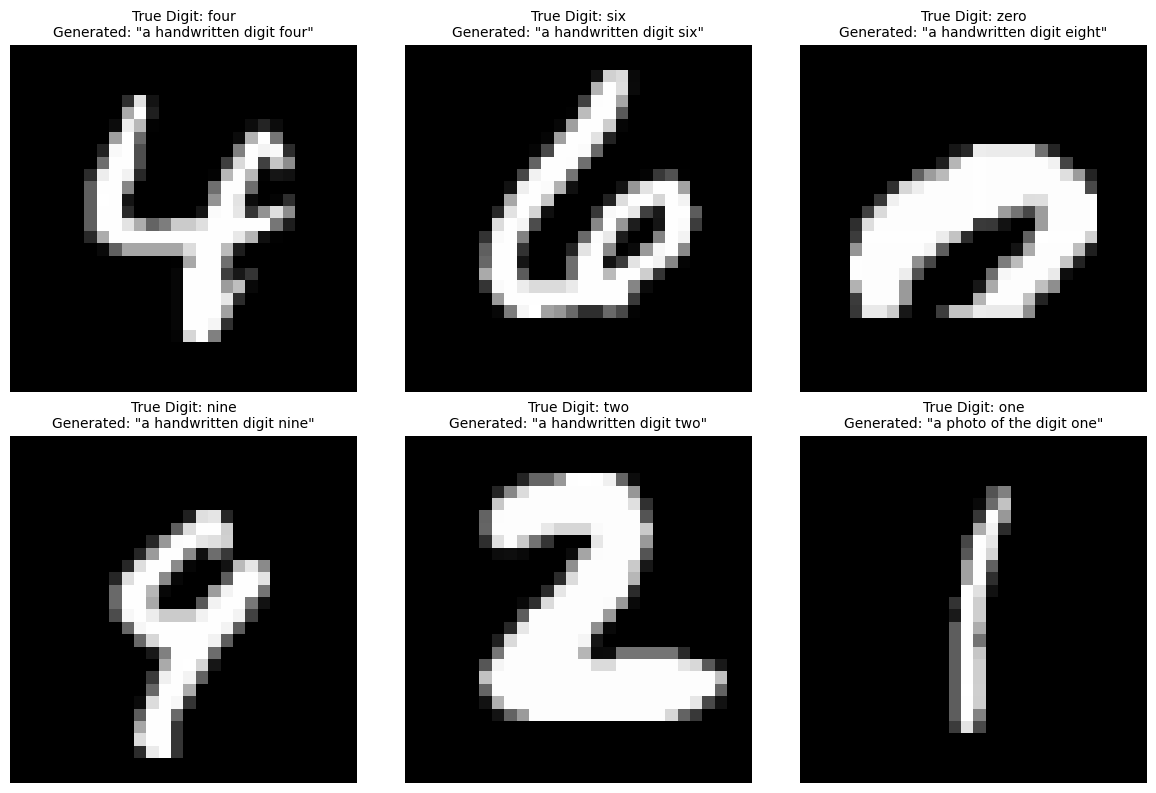


Saved plots: mnist_caption_training_loss.png, mnist_caption_predictions.png


In [24]:
# -------------------------------------------------------------------
# Visualize Test Predictions
# -------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
sample_indices = np.random.choice(len(test_images), 6, replace=False)

for ax, idx in zip(axes.ravel(), sample_indices):
    img = test_images[idx]
    true_label = class_names[int(y_test[test_idx[idx]])]
    pred_caption = generate_caption(img)

    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"True Digit: {true_label}\nGenerated: \"{pred_caption}\"", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close()

print("\nSaved plots: mnist_caption_training_loss.png, mnist_caption_predictions.png")